<a href="https://colab.research.google.com/github/anisafadillah-star/Praktikum-cv-2026-TimSakses/blob/main/modul01/M01_Pengenalan_CV_Tim%20Sakses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Klasifikasi Kematangan Tomat Berdasarkan Warna**



Program ini dibangun menggunakan Python, OpenCV, NumPy, dan Matplotlib untuk memproses citra sayur tomat yang dari UMKM Toko Sayuran Sukabumi. Program menerima masukan foto sampel tomat dari 5 sudut pengambilan (tampak atas, depan, belakang, kanan, dan kiri) di atas alas datar berwarna putih dengan 3 pecahayaan (Cahaya Alami Siang Hari Indoor, Cahaya Alami Outdoor dan Cahaya Tambahan dari Flash Handphone ).   Program akan melakukan segmentasi objek tomat, mengekstraksi fitur warna pada ruang warna HSV, serta mengklasifikasikan tingkat kematangan dan kualitas tomat secara otomatis ke dalam 3 kategori utama (Mentah, Matang, dan Busuk serta Cacat).


# **A1 Pemeriksa Lingkungan**


Sel ini berfungsi untuk memastikan bahwa seluruh pustaka (library) utama yang dibutuhkan dalam computer vision (OpenCV, NumPy, Matplotlib, dan scikit-image) sudah terpasang dengan baik beserta informasi versi masing-masing pustaka.

In [ ]:
import sys
import cv2
import numpy as np
import matplotlib
import skimage
import os

print("Praktikum Computer Vision Modul 1")
print("Python      :", sys.version.split()[0])
print("OpenCV      :", cv2.__version__)
print("NumPy       :", np.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-image:", skimage.__version__)

Praktikum Computer Vision Modul 1
Python      : 3.13.16
OpenCV      : 5.0.0
NumPy       : 2.1.3
Matplotlib  : 3.10.0
scikit-image: 0.25.2


# **A2 Membaca Citra dari Berkas**


In [ ]:
import os

# link Google Drive Anda
folder_id = "1OI7uYFSnD6mGNlKdt4mrggqywQkLcv0G"

# Buat folder
local_dataset_path = "/content/Dataseet-Tomat"

# Gunakan gdown untuk mengunduh seluruh isi folder Google Drive secara otomatis
print("Memulai proses pengunduhan dataset dari Google Drive...")
!gdown --folder {folder_id} -O {local_dataset_path} --remaining-ok

# Menampilkan isi folder yang berhasil diunduh
if os.path.exists(local_dataset_path):
    print("\nBerhasil mengunduh! Kategori yang ditemukan di lokal:")
    print(os.listdir(local_dataset_path))
else:
    print("Pengunduhan gagal, silakan periksa akses berbagi pada link Google Drive tersebut.")

Memulai proses pengunduhan dataset dari Google Drive...
Retrieving folder contents
Retrieving folder 1_0VC8amlCLTcqOoYD4oCVGF_VJIoUM5f tomat hijau mentah
Processing file 12lFOCscoYkj-9YxjDYPh7GiRupsF1ING tomathijaumentah1.jpeg
Processing file 1qBkU6IT-ltFatByWDJxT9foeEqGQhVWn tomathijaumentah2.jpeg
Processing file 1PWtU5TcdLbdaNjDxIIYiV3mlkNe4ulkL tomathijaumentah3.jpeg
Processing file 1nPmvh5anWLOxB8zRyArJHO7tVDDz36m2 tomathijaumentah4.jpeg
Processing file 19kGdJjMDgBdtexSQOfI7m0F1XtK7Xr8- tomathijaumentah5.jpeg
Processing file 1bi5fBuoAMBmu9tm_oFeFkrUb4UBjO8Rx tomathijaumentah6.jpeg
Processing file 1CdexON6ad_uyFTQRABAreaq9nH6x9OHT tomathijaumentah7.jpeg
Processing file 1neHC5iyDdaVlLK9UNs0wOnMKizneXIuK tomathijaumentah8.jpeg
Processing file 1K9OR4VW9PKzarEJ_vyL2mGneVzKLEWiS tomathijaumentah9.jpeg
Processing file 1QdiYjWaa6ErgUFaQiZno2d1lP5IsFA07 tomathijaumentah10.jpeg
Processing file 1n56rzTWuezeqmOEb56XwQRnRxUUYovP- tomathijaumentah11.jpeg
Processing file 1tKQUZqWHvUt0S-TSY02GUdrB

In [ ]:
import os
import cv2

base_path = '/content/Dataseet-Tomat'

if os.path.exists(base_path):
    # Cari file gambar secara dinamis dari subfolder apa pun yang ada
    path_sampel = None
    nama_file = None

    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                path_sampel = os.path.join(root, file)
                nama_file = file
                break
        if path_sampel:
            break

    if path_sampel:
        img = cv2.imread(path_sampel)
        if img is not None:
            print("=== ANALISIS STRUKTUR LARIK CITRA TOMAT ===")
            print("Berhasil membaca file :", nama_file)
            print("Jalur file lengkap    :", path_sampel)
            print("Tipe objek            :", type(img))
            print("Dimensi (Shape)       :", img.shape, "(Tinggi x Lebar x Kanal)")
            print("Tipe data             :", img.dtype)
            print("Nilai piksel minimum  :", img.min())
            print("Nilai piksel maksimum  :", img.max())
        else:
            print("Gagal membaca citra dari berkas:", path_sampel)
    else:
        print("Tidak ditemukan berkas gambar (.jpg/.png) di dalam", base_path)
else:
    print(f"Folder {base_path} tidak ditemukan.")

=== ANALISIS STRUKTUR LARIK CITRA TOMAT ===
Berhasil membaca file : tomatmerahmatang3.jpeg
Jalur file lengkap    : /content/Dataseet-Tomat/tomat merah matang/tomatmerahmatang3.jpeg
Tipe objek            : <class 'numpy.ndarray'>
Dimensi (Shape)       : (1600, 1600, 3) (Tinggi x Lebar x Kanal)
Tipe data             : uint8
Nilai piksel minimum  : 0
Nilai piksel maksimum  : 239


Hasil Pengamatan (A2):

1.   Berapa tinggi, lebar, dan jumlah kanal citra?
Berdasarkan output dimensi (1600, 1600, 3):

   *   Tinggi Citra: $1600$ piksel
   *   Lebar Citra: $1600$ piksel
   *   Jumlah Kanal Warna: $3$ kanal warna (format default BGR pada OpenCV)

2.   Mengapa rentang nilainya 0 sampai 255?

   *   Karena piksel citra disimpan menggunakan tipe data uint8 (Unsigned 8-bit Integer).
   *   Memori 8-bit menampung $2^8 = 256$ kombinasi nilai intensitas warna, yang membentang dari 0 (intensitas paling gelap/hitam) hingga 255 (intensitas paling terang/putih).
   *   Pada gambar tomatmerahmatang3.jpeg ini, nilai piksel minimum yang terdeteksi adalah 0 dan maksimumnya adalah 239.

3.  Ubah nama berkas pada cv2.imread menjadi nama yang salah, jalankan kembali, lalu jelaskan apa yang terjadi seandainya pemeriksaan if img is None tidak ada:

   *   Perilaku OpenCV: Fungsi *cv2.imread()* tidak melempar (raise) error saat lokasi atau nama berkas salah/tidak ditemukan, melainkan secara otomatis mengembalikan nilai None.
   *   Seandainya *if img is None* ditiadakan: Program akan tetap lanjut mengeksekusi baris berikutnya dan mengalami crash saat mencoba membaca atribut dari variabel yang bernilai None (seperti saat mengeksekusi *img.shape atau cv2.cvtColor*).Pesan galat yang muncul adalah *AttributeError*: *'NoneType' object has no attribute 'shape'.*
   *   Pentingnya Pemeriksaan: Kondisi if img is None berfungsi sebagai guard clause (penanganan kondisi darurat) agar program berhenti secara aman (fail-safe) dan langsung memberi peringatan bahwa file citra tidak terbaca sebelum proses pemrosesan citra dijalankan.

#**A3 - Menampilkan Citra dan Urutan Kanal BGR**


Menghitung gambar dan menampilkan contoh setiap kelas

tomat merah matang: 15 file


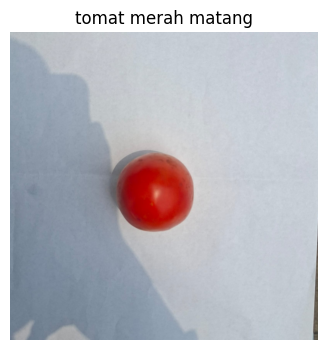

tomat hijau mentah: 15 file


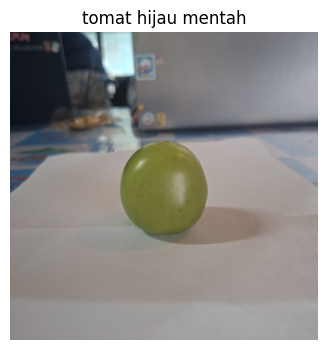

tomat merah busuk: 15 file


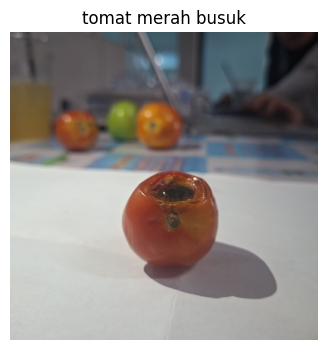

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

# Menggunakan jalur dataset lokal yang telah berhasil diunduh
dataset_path = '/content/Dataseet-Tomat'

if os.path.exists(dataset_path):
    for kelas in os.listdir(dataset_path):
        folder_kelas = os.path.join(dataset_path, kelas)

        if os.path.isdir(folder_kelas):
            gambar = os.listdir(folder_kelas)
            print(f'{kelas}: {len(gambar)} file')

            if len(gambar) > 0:
                path_gambar = os.path.join(folder_kelas, gambar[0])

                # Simpan citra asli berformat BGR ke variabel img
                img = cv2.imread(path_gambar)

                if img is not None:
                    # Gunakan variabel terpisah (img_show) khusus untuk tampilan agar 'img' tetap BGR asli
                    img_show = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                    plt.figure(figsize=(4, 4))
                    plt.imshow(img_show)
                    plt.title(kelas)
                    plt.axis('off')
                    plt.show()
else:
    print(f"Folder dataset di {dataset_path} tidak ditemukan. Pastikan Anda telah menjalankan cell pengunduhan dataset terlebih dahulu.")

Membandingkan kanal warna BGR dan RGB

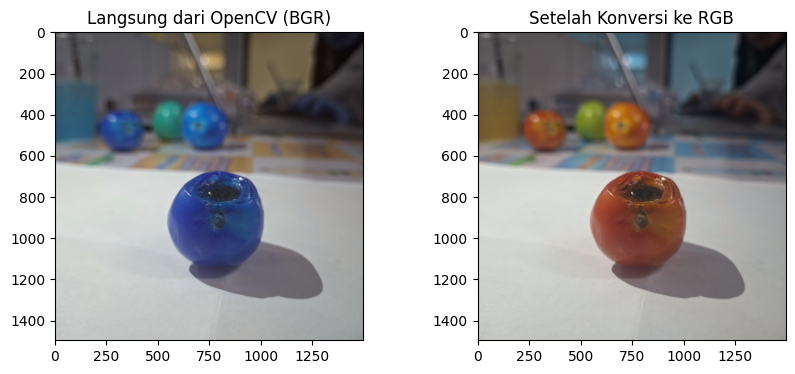

In [ ]:
import cv2
import matplotlib.pyplot as plt

# 1. Konversi citra dari BGR (OpenCV) ke RGB (Matplotlib)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Buat subplot untuk membandingkan tampilan BGR vs RGB
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Panel Kiri: Ditampilkan langsung dari format OpenCV (BGR)
ax[0].imshow(img)
ax[0].set_title("Langsung dari OpenCV (BGR)")

# Panel Kanan: Ditampilkan setelah dikonversi ke RGB
ax[1].imshow(img_rgb)
ax[1].set_title("Setelah Konversi ke RGB")

# Hilangkan sumbu koordinat agar rapi
for a in ax:
    a.axis("on")

plt.show()

Hasil Pengamatan (A3)

1.   Mengapa warna pada panel kiri tampak kebiruan?

*   Pustaka OpenCV secara default menyimpan data piksel citra dalam urutan kanal warna BGR (Blue, Green, Red).
*    Di sisi lain, fungsi imshow() dari Matplotlib membaca dan menampilkan matriks citra dengan mengasumsikan urutan kanal RGB (Red, Green, Blue).
*   Ketika citra BGR langsung ditayangkan dengan Matplotlib tanpa konversi, posisi kanal Merah (Red) dan Biru (Blue) tertukar, sehingga area citra yang seharusnya berwarna merah/hangat (seperti warna buah tomat matang) terlihat kebiruan/dingin.
2.   Kesalahan apa yang dapat muncul pada proyek bila fitur warna dihitung tanpa memperhatikan urutan kanal?

*   Kesalahan Ekstraksi Fitur: Nilai rata-rata, varians, atau histogram untuk kanal Red dan Blue akan tertukar.
*   Kesalahan Klasifikasi: Pada proyek klasifikasi tingkat kematangan tomat, tomat matang (berwarna dominan merah) dapat terdeteksi salah sebagai objek berwarna biru/gelap atau masuk ke kategori kelas yang salah.
*   Koreksi Ruang Warna Lain: Jika citra BGR dikonversi ke ruang warna HSV atau Lab menggunakan rumus standar RGB, hasil transformasi warnanya akan keliru dan merusak seluruh logika segmentasi berbasis warna.

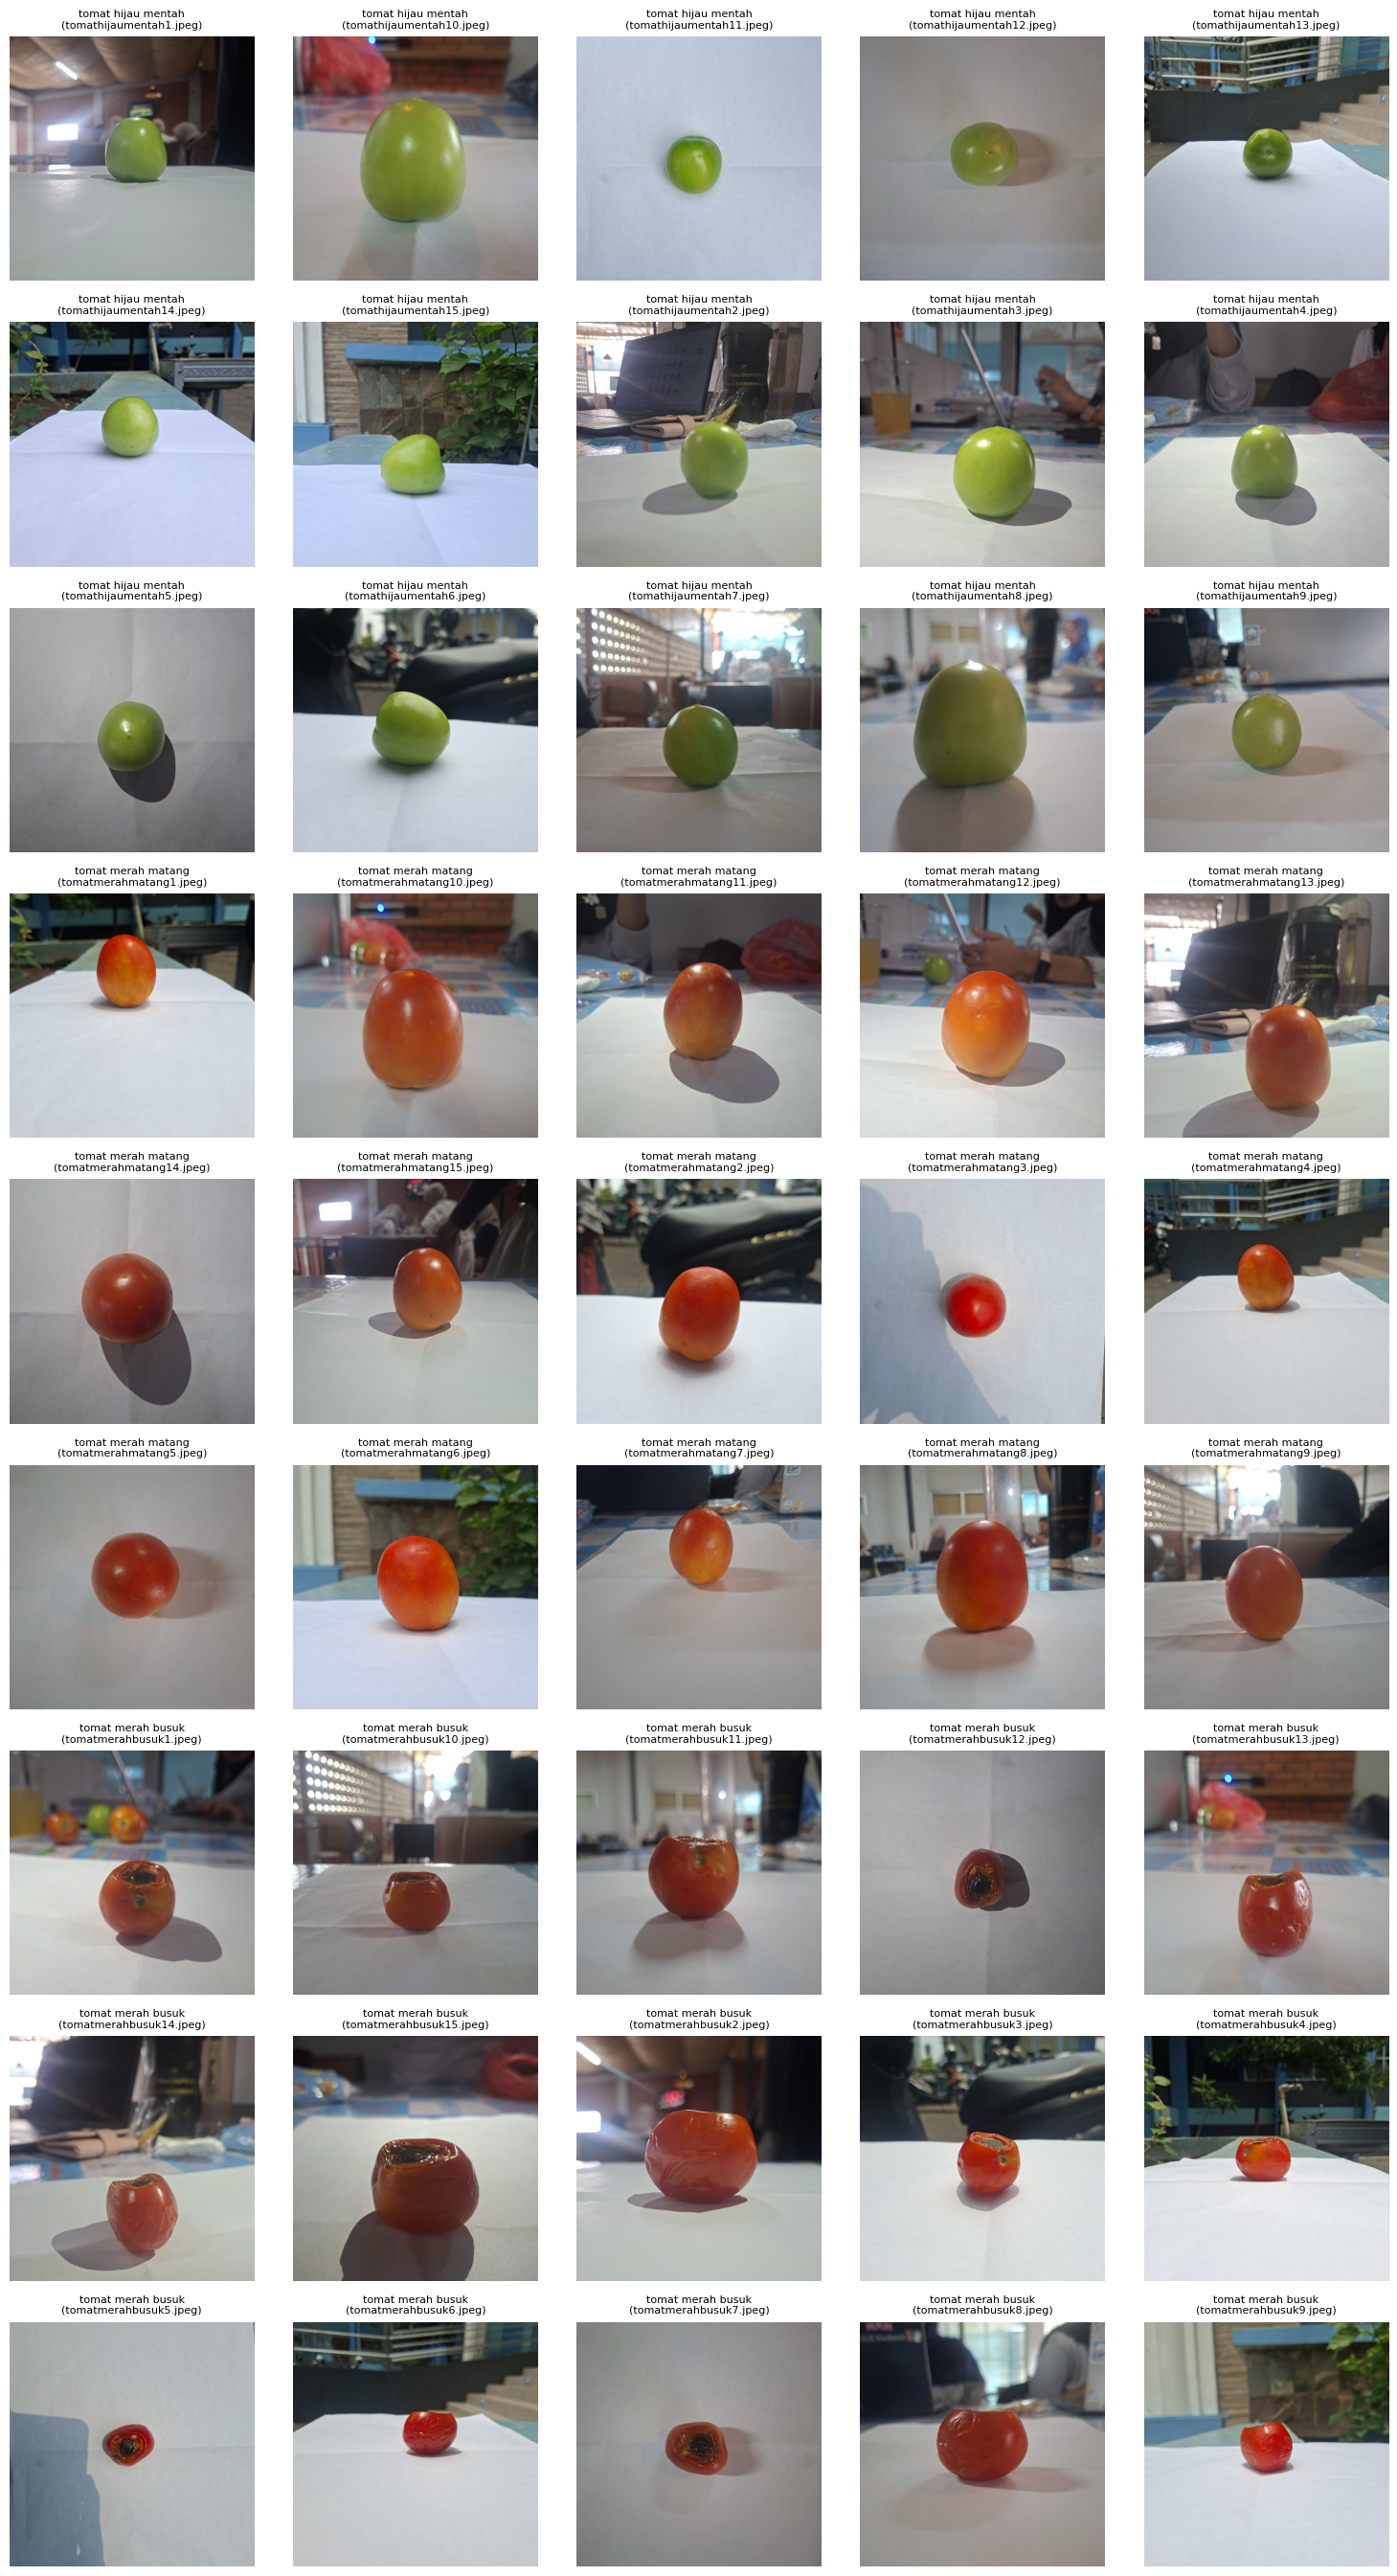

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt

dataset_path = "/content/Dataseet-Tomat"
kategori_list = ['tomat hijau mentah', 'tomat merah matang', 'tomat merah busuk']

# 1. Hitung total seluruh gambar untuk menentukan ukuran figure
total_gambar = 0
for kat in kategori_list:
    folder = os.path.join(dataset_path, kat)
    if os.path.exists(folder):
        files = [f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        total_gambar += len(files)

# 2. Tampilkan seluruh foto dalam bentuk Grid
if total_gambar > 0:
    # Mengatur jumlah kolom (misal 5 kolom)
    cols = 5
    rows = (total_gambar + cols - 1) // cols

    plt.figure(figsize=(15, 3 * rows))
    idx = 1

    for kat in kategori_list:
        folder = os.path.join(dataset_path, kat)
        if os.path.exists(folder):
            files = sorted([f for f in os.listdir(folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
            for file in files:
                img_path = os.path.join(folder, file)
                img = cv2.imread(img_path)

                if img is not None:
                    # Konversi BGR ke RGB agar warna tidak kebiruan
                    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                    plt.subplot(rows, cols, idx)
                    plt.imshow(img_rgb)
                    plt.title(f"{kat}\n({file})", fontsize=8)
                    plt.axis('off')
                    idx += 1

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan file gambar di dalam folder dataset.")

Seluruh sampel citra dari 3 kategori (tomat hijau mentah, tomat merah matang, dan tomat merah busuk) berhasil dimuat dan ditayangkan dalam tata letak kisi (grid) 5 kolom secara teratur.

# **A4 - Struktur Larik dan Akses Piksel**
Memahami representasi matematika dan memori dari citra digital sebagai matriks NumPy (array multi-dimensi). Melalui kode ini, kita dapat mengakses koordinat piksel secara spesifik, mengambil nilai kanal warna penyusunnya, memisahkan kanal warna (B, G, R), serta mengonversi citra berwarna menjadi citra aras keabuan (grayscale).

In [ ]:
import cv2

# 1. Properti Utama Citra
tinggi, lebar, kanal = img.shape
print(f"Dimensi : Tinggi {tinggi} px, Lebar {lebar} px, {kanal} kanal")
print("Jumlah elemen :", img.size)
print("Memori (byte) :", img.nbytes)
print("-" * 50)

# 2. Akses Piksel pada Beberapa Koordinat Spesifik
titik_sampel = [(100, 200), (50, 50), (150, 100)]

for y, x in titik_sampel:
    b, g, r = img[y, x]
    print(f"Piksel pada (y={y}, x={x}) -> BGR: [{b}, {g}, {r}] | Kanal Merah (R): {r}")

print("-" * 50)

# 3. Pemisahan Kanal dan Konversi ke Grayscale
b, g, r = cv2.split(img)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

print("Shape citra berwarna (BGR) :", img.shape)
print("Shape satu kanal (Blue)    :", b.shape)
print("Shape aras keabuan (Gray)  :", gray.shape, "| Tipe Data:", gray.dtype)

Dimensi : Tinggi 1498 px, Lebar 1498 px, 3 kanal
Jumlah elemen : 6732012
Memori (byte) : 6732012
--------------------------------------------------
Piksel pada (y=100, x=200) -> BGR: [141, 155, 151] | Kanal Merah (R): 151
Piksel pada (y=50, x=50) -> BGR: [165, 176, 173] | Kanal Merah (R): 173
Piksel pada (y=150, x=100) -> BGR: [160, 171, 168] | Kanal Merah (R): 168
--------------------------------------------------
Shape citra berwarna (BGR) : (1498, 1498, 3)
Shape satu kanal (Blue)    : (1498, 1498)
Shape aras keabuan (Gray)  : (1498, 1498) | Tipe Data: uint8


Hasil Pengamatan (A4)

1.   Mengapa jumlah elemen sama dengan jumlah byte memori?

*   Berdasarkan output eksekusi, jumlah elemen adalah 6.732.012 dan ukuran memorinya adalah 6.732.012 byte.
*   Ukurannya sama persis karena piksel citra disimpan menggunakan tipe data uint8 (Unsigned 8-bit Integer).Ukurannya sama persis karena piksel citra disimpan menggunakan tipe data uint8 (Unsigned 8-bit Integer).
*   Pada tipe data 8-bit, $1\text{ elemen piksel} = 1\text{ byte}$ memori. Sehingga total byte memori bernilai sama dengan total seluruh elemen matriks ($1498 \times 1498 \times 3 = 6.732.012$).

2.   Pencatatan Nilai Piksel pada Titik/Koordinat Lain:

*   Titik 1 (y=100, x=200): Nilai BGR [141, 155, 151] | Nilai Kanal Merah (R): 151
*   Titik 2 (y=50, x=50): Nilai BGR [165, 176, 173] | Nilai Kanal Merah (R): 173
*   Titik 3 (y=150, x=100): Nilai BGR [160, 171, 168] | Nilai Kanal Merah (R): 168
3. Perbandingan Shape (Dimensi Matriks):

*   Citra Berwarna (BGR): Berdimensi 3D (1498, 1498, 3) — Memiliki 3 kanal warna (Blue, Green, Red).
*   Satu Kanal (Blue): Berdimensi 2D (1498, 1498) — Hanya berisi matriks intensitas 1 kanal warna saja tanpa dimensi kanal ketiga.
*   Aras Keabuan (Grayscale): Berdimensi 2D (1498, 1498) dengan tipe data uint8 — Hanya berisi intensitas kecerahan/derajat keabuan dari $0$ hingga $255$.

# **A5 - Region of Interest (ROI): View dan Salinan**

Memahami perbedaan mendasar antara pembuatan area perhatian (Region of Interest / ROI) secara View (referensi memori langsung) dan secara Salinan Independen (.copy()). Pemahaman ini sangat krusial dalam pemrosesan citra digital untuk mencegah kerusakan data citra utama secara tidak sengaja saat dilakukan pemotongan (crop) atau pengeditan area tertentu.


In [ ]:
import cv2

img = cv2.imread(path_sampel)

if img is None:
    raise ValueError("Citra tidak berhasil dibaca.")

# Membuat ROI sebagai view dan salinan
roi = img[50:250, 100:400]
roi_salinan = img[50:250, 100:400].copy()

# Memeriksa bahwa area awal memiliki nilai yang sama
print("Rata-rata area sebelum diubah:", roi.mean())

# Mengubah view menjadi hitam
roi[:] = 0
print("Rata-rata area asli setelah view diubah:",
      img[50:250, 100:400].mean())

# Mengubah salinan menjadi putih
roi_salinan[:] = 255
print("Rata-rata salinan setelah diubah:", roi_salinan.mean())

# Membaca ulang citra asli dari berkas
img = cv2.imread(path_sampel)
print("Rata-rata area setelah citra dimuat ulang:",
      img[50:250, 100:400].mean())


Rata-rata area sebelum diubah: 186.3428888888889
Rata-rata area asli setelah view diubah: 0.0
Rata-rata salinan setelah diubah: 255.0
Rata-rata area setelah citra dimuat ulang: 186.3428888888889


Hasil Pengamatan (A5)
1.   Mengapa nilai rata-rata area asli menjadi 0 setelah roi diubah?

*   Berdasarkan hasil eksekusi, nilai rata-rata area asli awal adalah 186.34 dan turun menjadi 0.0 setelah variabel roi diubah.
*   Hal ini terjadi karena pemotongan (slicing) matriks NumPy tanpa pemanggilan fungsi .copy() hanya menghasilkan sebuah View (referensi/alamat memori yang sama dengan citra asli img).
*   Ketika elemen-elemen pada roi diubah menjadi $0$ (roi[:] = 0), perubahan tersebut langsung berdampak pada matriks img asli di area koordinat yang sama.

2.   Perbedaan Percobaan Menggunakan roi_salinan (.copy()):

*   Ketika operasi perubahan dilakukan pada roi_salinan (misalnya diubah menjadi $255.0$), nilai rata-rata pada roi_salinan berubah menjadi 255.0, namun area pada citra asli img tidak mengalami perubahan sama sekali (tetap bernilai 186.34).
*   Hal ini terjadi karena pemanggilan .copy() membuat alokasi memori baru yang sepenuhnya terpisah/independen dari citra utama img.

3. Mengapa hal ini penting ketika menyusun rangkaian praproses pada proyek?

*   Mencegah Kerusakan Data Mentah (Data Corruption): Dalam alur praproses proyek (seperti pemotongan area tomat/ROI, augmentasi gambar, atau pembersihan noise), penggunaan View secara tidak sengaja dapat merusak data citra asli img.
*    Keamanan Alur Pemrosesan (Pipeline): Penggunaan .copy() memastikan bahwa citra asli tetap utuh dan dapat digunakan kembali untuk metode ekstraksi fitur atau model klasifikasi lain tanpa perlu membaca ulang file dari disk.

# **A6 - Anotasi dan Penyimpanan Citra**
Mempelajari teknik memberikan anotasi visual pada citra (seperti menggambar kotak pembatas/ROI dan menambahkan teks) menggunakan fungsi bawaan OpenCV, serta memahami perbedaan karakteristik penyimpanan berkas citra dalam format PNG (lossless) dan JPEG (lossy) dari segi ukuran memori dan kualitas data piksel.

In [ ]:
import os
import cv2
import numpy as np

# 1. Pastikan citra asli dan grayscale dimuat kembali
img = cv2.imread(path_sampel)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Save berkas asli dalam format PNG terlebih dahulu untuk perbandingan
cv2.imwrite("tomat.png", img)

# 2. Membuat anotasi ROI pada salinan gambar
anotasi = img.copy()
# OpenCV menggunakan koordinat (x, y) -> (kolom, baris)
cv2.rectangle(anotasi, (100, 50), (400, 250), (0, 255, 0), 2)
cv2.putText(anotasi, "ROI", (105, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

# 3. Menyimpan citra dalam berbagai format dan kualitas
cv2.imwrite("tomat_roi.png", anotasi)
cv2.imwrite("tomat_q90.jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 90])
cv2.imwrite("tomat_gray.png", gray)

# 4. Memeriksa ukuran berkas (dalam KB)
print("=== PERBANDINGAN UKURAN BERKAS ===")
for nama in ["tomat.png", "tomat_q90.jpg", "tomat_gray.png", "tomat_roi.png"]:
    if os.path.exists(nama):
        print(f"{nama:15s} {os.path.getsize(nama) / 1024:8.1f} KB")

# 5. Membandingkan selisih piksel PNG vs JPEG
jpg = cv2.imread("tomat_q90.jpg")
selisih = np.abs(img.astype(int) - jpg.astype(int)).mean()
print("\nSelisih rata-rata piksel PNG vs JPEG:", round(selisih, 2))

=== PERBANDINGAN UKURAN BERKAS ===
tomat.png         1609.1 KB
tomat_q90.jpg      138.0 KB
tomat_gray.png     666.4 KB
tomat_roi.png     1613.9 KB

Selisih rata-rata piksel PNG vs JPEG: 0.09


Hasil Pengamatan (A6)

1.   Perbandingan Urutan Koordinat cv2.rectangle vs Slicing NumPy (Kode A5):

*    cv2.rectangle (OpenCV): Menggunakan urutan koordinat kartesian (x, y) atau (kolom, baris). Contoh: (x1, y1), (x2, y2).
*   Slicing NumPy (Kode A5): Menggunakan urutan indeks matriks [baris, kolom] atau [y, x]. Contoh: [y1:y2, x1:x2].

2.   Perbandingan Ukuran Berkas & Selisih Piksel (PNG vs JPEG):

*   Mengapa Berkas JPEG Lebih Kecil:
 Berdasarkan output eksekusi, ukuran berkas tomat.png (1609.1 KB) jauh lebih besar dibandingkan tomat_q90.jpg (138.0 KB). Hal ini terjadi karena format JPEG menggunakan metode kompresi lossy (menghilangkan sebagian frekuensi tinggi/detail warna yang kurang sensitif bagi mata manusia demi menekan ukuran berkas), sedangkan PNG menggunakan kompresi lossless (mempertahankan seluruh informasi piksel secara utuh).
*    Mengapa Selisih Piksel Tidak Nol: Berdasarkan perhitungan, selisih rata-rata piksel antara PNG dan JPEG adalah 0.09. Selisih ini tidak nol karena efek kompresi lossy pada JPEG mengubah sedikit nilai intensitas piksel asli untuk menghemat ruang penyimpanan.

3. Format yang Sebaiknya Digunakan untuk Menyimpan Citra Mentah Proyek:

*   Untuk menyimpan citra mentah (raw data) atau hasil praproses pada proyek Computer Vision, format PNG (atau format lossless lain seperti BMP/TIFF) sangat direkomendasikan.
*   Format PNG memastikan nilai intensitas piksel tidak mengalami perubahan atau distorsi, sehingga fitur warna dan tekstur yang diekstraksi untuk analisis atau pelatihan model klasifikasi tetap akurat.

# **B1-Membaca dan Mengamati Citra Proyek**
Kode ini bertujuan untuk mempraktikkan pengunggahan citra secara mandiri (upload) dari perangkat lokal ke lingkungan Google Colab menggunakan fitur google.colab.files.upload(), kemudian melakukan inspeksi properti matriks citra (seperti dimensi fisik, tipe data, jangkauan piksel, dan rata-rata nilai tiap kanal warna BGR) serta menampilkan visualisasinya secara proporsional.

In [ ]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# 1. Unggah berkas gambar dari komputer/telepon genggam
unggah = files.upload()

if unggah:
    path = list(unggah.keys())[0]

    # 2. Baca citra yang diunggah
    citra = cv2.imread(path)
    if citra is None:
        raise FileNotFoundError("Citra tidak terbaca.")

    # 3. Kuantifikasi & Resizing hanya untuk tampilan
    h, w = citra.shape[:2]
    skala = 800 / max(h, w)

    if skala < 1:
        tampil = cv2.resize(citra, (int(w * skala), int(h * skala)), interpolation=cv2.INTER_AREA)
    else:
        tampil = citra

    # 4. Tampilkan informasi properti citra
    print("Shape asli                  :", citra.shape, citra.dtype)
    print("Shape tampil                :", tampil.shape)
    print("Min/maks nilai piksel       :", citra.min(), citra.max())
    print("Rata-rata per kanal (B,G,R) :", citra.mean(axis=(0, 1)).round(1))

    # 5. Visualisasi citra
    plt.figure(figsize=(6, 6))
    plt.imshow(cv2.cvtColor(tampil, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(f"Visualisasi Citra: {path}")
    plt.show()

In [ ]:

import os
import cv2

dataset_path = "/content/Dataseet-Tomat"

kategori_list = [
    "tomat hijau mentah",
    "tomat merah matang",
    "tomat merah busuk"
]

ekstensi_gambar = (".jpg", ".jpeg", ".png")

for nomor, kategori in enumerate(kategori_list, start=1):
    folder = os.path.join(dataset_path, kategori)

    print(f"\n{'=' * 55}")
    print(f"CITRA PROYEK {nomor}: {kategori.upper()}")
    print("=" * 55)

    if not os.path.isdir(folder):
        print("Folder kelas tidak ditemukan:", folder)
        continue

    # Mengambil satu gambar dari setiap kelas
    daftar_file = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith(ekstensi_gambar)
    ])

    if not daftar_file:
        print("Tidak ada file gambar di folder ini.")
        continue

    nama_file = daftar_file[0]
    path_gambar = os.path.join(folder, nama_file)

    # Membaca citra dalam format BGR
    img = cv2.imread(path_gambar)

    if img is None:
        print("Gagal membaca citra:", path_gambar)
        continue

    tinggi, lebar, kanal = img.shape
    ukuran_kb = os.path.getsize(path_gambar) / 1024

    # Informasi piksel dan rata-rata kanal BGR
    rata_rata_bgr = cv2.mean(img)[:3]

    print("Kelas                 :", kategori)
    print("Nama file             :", nama_file)
    print("Sumber/perangkat      : Foto dataset proyek")
    print("Format                :", os.path.splitext(nama_file)[1])
    print("Ukuran berkas         :", round(ukuran_kb, 2), "KB")
    print("Shape                 :", img.shape)
    print("Tinggi                :", tinggi, "piksel")
    print("Lebar                 :", lebar, "piksel")
    print("Jumlah kanal          :", kanal)
    print("Tipe data             :", img.dtype)
    print("Nilai piksel minimum  :", img.min())
    print("Nilai piksel maksimum :", img.max())

    # Memeriksa apakah koordinat (baris 100, kolom 200) tersedia
    if tinggi > 100 and lebar > 200:
        print("Nilai BGR (100, 200)  :", img[100, 200].tolist())
    else:
        print("Nilai BGR (100, 200)  : Koordinat di luar citra")

    print("Rata-rata kanal BGR   :",
          tuple(round(float(v), 2) for v in rata_rata_bgr))

    # Tampilkan informasi kondisi pengambilan secara manual
    print("Pencahayaan           : Isi sesuai foto yang dipilih")
    print("Sudut pengambilan     : Isi sesuai foto yang dipilih")
    print("Wajah/identitas       : Periksa citra secara visual")



CITRA PROYEK 1: TOMAT HIJAU MENTAH
Kelas                 : tomat hijau mentah
Nama file             : tomathijaumentah1.jpeg
Sumber/perangkat      : Foto dataset proyek
Format                : .jpeg
Ukuran berkas         : 71.16 KB
Shape                 : (1496, 1496, 3)
Tinggi                : 1496 piksel
Lebar                 : 1496 piksel
Jumlah kanal          : 3
Tipe data             : uint8
Nilai piksel minimum  : 1
Nilai piksel maksimum : 255
Nilai BGR (100, 200)  : [98, 105, 125]
Rata-rata kanal BGR   : (121.76, 124.72, 125.11)
Pencahayaan           : Isi sesuai foto yang dipilih
Sudut pengambilan     : Isi sesuai foto yang dipilih
Wajah/identitas       : Periksa citra secara visual

CITRA PROYEK 2: TOMAT MERAH MATANG
Kelas                 : tomat merah matang
Nama file             : tomatmerahmatang1.jpeg
Sumber/perangkat      : Foto dataset proyek
Format                : .jpeg
Ukuran berkas         : 74.12 KB
Shape                 : (1500, 1500, 3)
Tinggi                : 15

Hasil Pengamatan & Analisis Properti Citra Proyek

1.   Perbandingan Dimensi & Ukuran Berkas:

*   Tomat Hijau Mentah (tomathijaumentah1.jpeg):
    *   Berdimensi 1496×1496×3 piksel dengan ukuran berkas 71.16 KB.
*   Tomat Merah Matang (tomatmerahmatang1.jpeg):
    *   Berdimensi 1500×1500×3 piksel dengan ukuran berkas 74.12 KB.
*   Tomat Merah Busuk (tomatmerahbusuk1.jpeg):
    *   Berdimensi 1496×1496×3 piksel dengan ukuran berkas 75.21 KB.

Ketiga sampel citra menggunakan tipe data uint8 (Unsigned 8-bit Integer) dengan rentang intensitas nilai piksel mendekati 0 hingga 255.

2.   Analisis Nilai Piksel Sampel Koordinat (y=100,x=200):
        
*   Tomat Hijau Mentah: BGR [98, 105, 125]
    *   Kanal Merah (125) dan Green (105) lebih tinggi dibanding Blue (98).
*   Tomat Merah Matang: BGR [52, 37, 18]
    *   Titik koordinat ini berada pada area bayangan/latar yang gelap di sekitar objek tomat.
*   Tomat Merah Busuk: BGR [81, 82, 86]
    *   Nilai BGR relatif seimbang yang menunjukkan area latar belakang netral/pencahayaan sedang.

3. Analisis Rata-Rata Kanal Warna BGR:

*   Tomat Hijau Mentah:
    *   Rata-rata BGR = (121.76, 124.72, 125.11)
    *   Menunjukkan distribusi warna yang seimbang antara alas putih dan warna hijau alami buah.
*   Tomat Merah Matang:
    *   Rata-rata BGR = (155.52, 155.47, 154.98)
    *   Memiliki tingkat intensitas kecerahan (luminance) keseluruhan yang paling tinggi di antara ketiga sampel.
*   Tomat Merah Busuk:
    *   Rata-rata BGR = (126.87, 129.93, 135.45)
    *   Kanal Red (135.45) terlihat paling dominan dibandingkan Blue (126.87) dan Green (129.93), yang menandakan warna dasar merah buah yang disertai penurunan kecerahan akibat area kebusukan/bercak gelap.